In [1]:
import numpy as np
import pandas as pd
import mne

from neurodsp.filt import filter_signal
from neurodsp.plts import plot_time_series
from neurodsp.sim import sim_combined

from bycycle import Bycycle
from bycycle.cyclepoints import find_extrema, find_zerox
from bycycle.cyclepoints.zerox import find_flank_zerox
from bycycle.plts import plot_cyclepoints_array
from bycycle.utils.download import load_bycycle_data
from bycycle.plts import plot_feature_categorical
from bycycle.utils import flatten_dfs

pd.options.display.max_columns = 10

from scipy import stats

from pathlib import Path

In [2]:
ALL_CHANNELS_26 = [
    'Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FC3', 'FCz', 'FC4',
    'T7', 'C3', 'Cz', 'C4', 'T8', 'CP3', 'CPz', 'CP4', 'P7', 'P3',
    'Pz', 'P4', 'P8', 'O1', 'Oz', 'O2',
]

# path to the eeg data
EEG_ROOT = Path('/oscar/data/sjones/shared/TDBRAIN_v3/TDBRAIN_Dataset_V3_1')

# path to the meta data - includes info. about age, gender, remitter/responder status
METADATA_PATH = Path('/oscar/data/sjones/shared/TDBRAIN_v3/TDBRAIN_participants_V3.xlsx')

meta = pd.read_excel(METADATA_PATH)

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 50)

print(meta.shape)
print(meta.columns.tolist())
meta.head(50)
print(pd.crosstab(meta['Responder'], meta['Remitter'], dropna=False))


# ACTIVE_CONDITION = 'ec' 

# RESPONSE_VAR = 'Remitter'
# # RESPONSE_VAR = 'Responder'

# N_RANDOM_WINDOWS = 160 * 10
# NUM_CHANNELS = 6
# # FIXED_CHANNELS = ['Fz', 'Pz', 'Oz']
# FIXED_CHANNELS = ['Fz', 'FCz', 'Pz', 'Oz', 'Cz', 'F7']
# # FIXED_CHANNELS = ['FC3', 'FCz', 'FC4']
# WINDOW_SAMPLES = 5000
# FORECAST_HORIZON = 1000
# N_RANDOM_STATES = 100
# RNG_SEED = 29

(1363, 106)
['TDBRAIN_ID', 'DISC/REP', 'indication', 'formal_status', 'Dataset', 'Consent', 'sessSeason', 'sessTime', 'Responder', 'Remitter', 'age', 'gender', 'sessID', 'nrSessions', 'neoFFI_q1', 'neoFFI_q2', 'neoFFI_q3', 'neoFFI_q4', 'neoFFI_q5', 'neoFFI_q6', 'neoFFI_q7', 'neoFFI_q8', 'neoFFI_q9', 'neoFFI_q10', 'neoFFI_q11', 'neoFFI_q12', 'neoFFI_q13', 'neoFFI_q14', 'neoFFI_q15', 'neoFFI_q16', 'neoFFI_q17', 'neoFFI_q18', 'neoFFI_q19', 'neoFFI_q20', 'neoFFI_q21', 'neoFFI_q22', 'neoFFI_q23', 'neoFFI_q24', 'neoFFI_q25', 'neoFFI_q26', 'neoFFI_q27', 'neoFFI_q28', 'neoFFI_q29', 'neoFFI_q30', 'neoFFI_q31', 'neoFFI_q32', 'neoFFI_q33', 'neoFFI_q34', 'neoFFI_q35', 'neoFFI_q36', 'neoFFI_q37', 'neoFFI_q38', 'neoFFI_q39', 'neoFFI_q40', 'neoFFI_q41', 'neoFFI_q42', 'neoFFI_q43', 'neoFFI_q44', 'neoFFI_q45', 'neoFFI_q46', 'neoFFI_q47', 'neoFFI_q48', 'neoFFI_q49', 'neoFFI_q50', 'neoFFI_q51', 'neoFFI_q52', 'neoFFI_q53', 'neoFFI_q54', 'neoFFI_q55', 'neoFFI_q56', 'neoFFI_q57', 'neoFFI_q58', 'neoFFI_q59',

In [3]:
# viewing subjects that have any remitter value
has_remit = meta[meta['Remitter'].notna()].copy()
print(len(has_remit), 'subjects with a remitter value')
print(has_remit['Remitter'].value_counts())

269 subjects with a remitter value
Remitter
1.0    141
0.0    128
Name: count, dtype: int64


In [4]:
has_respond = meta[meta['Responder'].notna()].copy()
print(len(has_respond), 'subjects with a responder value')
print(has_respond['Responder'].value_counts())

273 subjects with a responder value
Responder
1.0    182
0.0     91
Name: count, dtype: int64


In [5]:
# confirming that the eeg files are in the correct folders 
found_ec = []
missing_ec = []

found_eo = []
missing_eo = []

for subj in has_remit['TDBRAIN_ID'].unique(): 
    subj = str(subj)
    folder = EEG_ROOT / subj / 'ses-1' / 'eeg' / 'preprocessed'

    if folder.exists(): 
        files_ec = list(folder.glob('*restEC*_eeg.npy'))
        files_eo = list(folder.glob('*restEO*_eeg.npy'))
    else: 
        files_ec = []
        files_eo = []
    
    if len(files_ec) > 0: 
        found_ec.append(subj)
    else:
        missing_ec.append(subj)

    if len(files_eo) > 0:
        found_eo.append(subj)
    else:
        missing_eo.append(subj)

print('EC:', len(found_ec), 'found,', len(missing_ec), 'missing')
print('EO:', len(found_eo), 'found,', len(missing_eo), 'missing')

EC: 249 found, 5 missing
EO: 249 found, 5 missing


In [6]:
subj = found_ec[0]

folder = EEG_ROOT / subj / 'ses-1' / 'eeg' / 'preprocessed'

files = list(folder.glob('*restEC*_eeg.npy'))

data = np.load(files[0])

print(data.shape)

(17, 26, 2500)


In [7]:
# loading ec data
ec_data = {}
for subj in found_ec: 
    folder = EEG_ROOT / subj / 'ses-1' / 'eeg' / 'preprocessed'
    files = list(folder.glob('*restEC*_eeg.npy'))

    ec_data[subj] = np.load(files[0])

In [8]:
# loading eo data
eo_data = {}
for subj in found_eo: 
    folder = EEG_ROOT / subj / 'ses-1' / 'eeg' / 'preprocessed'
    files = list(folder.glob('*restEO*_eeg.npy'))

    eo_data[subj] = np.load(files[0])

In [9]:
has_remit['TDBRAIN_ID'] = has_remit['TDBRAIN_ID'].astype(str)

# TDBRAIN_ID set as a row instead of a column 
labels = has_remit.drop_duplicates(subset='TDBRAIN_ID').set_index('TDBRAIN_ID')

# labels.loc selects data from the table by label  
print(labels.loc[found_ec[0], 'Remitter'])
print(labels.loc[found_ec[0], 'Responder'])

1.0
1.0


In [10]:
print(data.ndim)     # number of dimensions: 2 means a 2D array
print(data.shape)    # the size of each dimension

3
(17, 26, 2500)


In [11]:
# load data 

# sig = load_bycycle_data('ca1.npy', folder='data')
# fs = 500

# # Filter settings
# f_theta = (4, 8)
# f_alpha = (8, 12)
# f_beta = (13, 30)

# f_lowpass = 30
# n_seconds_filter = .1

# # Lowpass filter
# sig_low = filter_signal(sig, fs, 'lowpass', f_lowpass,
#                         n_seconds=n_seconds_filter, remove_edges=False)

# # Plot signal
# times = np.arange(0, len(sig)/fs, 1/fs)
# xlim = (2, 5)
# tidx = np.logical_and(times >= xlim[0], times < xlim[1])

# plot_time_series(times[tidx], [sig[tidx], sig_low[tidx]], colors=['k', 'k'], alpha=[.5, 1], lw=2)

In [12]:
# bycycle analysis - 3d array (n_channels, n_epochs, n_timepoints)

n_seconds = 5
fs = 500

f_range = (8, 12) # potentially change to theta or beta 

n_channels = 26
n_epochs = 17

In [13]:
# original code but took too long to run (first 170 subjects processed through this)
#  from bycycle import BycycleGroup
# from joblib import Parallel, delayed
# from tqdm import tqdm

# f_alpha = (8,12)

# all_cycles = []
# for subj in remaining:
#     data = ec_data[subj]

#     for epoch in range(data.shape[0]): 
#         bg = BycycleGroup()
#         bg.fit(data[epoch], fs, f_alpha, n_jobs = 16)


#         for ch in range(data.shape[1]):
#             df = bg.df_features[ch].copy()

#             df['subject_id'] = subj 
#             df['epoch'] = epoch 
#             df['channel'] = ch
#             df['remitter'] = labels.loc[subj, 'Remitter']
#             df['responder'] = labels.loc[subj, 'Responder']


#             all_cycles.append(df)

# df_cycles = pd.concat(all_cycles) # stack all the tables into one big table 
# df_bursts = df_cycles[df_cycles['is_burst']]


In [14]:
# from bycycle import BycycleGroup
# from joblib import Parallel, delayed
# from tqdm import tqdm

# f_alpha = (8, 12)

# def process_subject(subj):
#     data = ec_data[subj]
#     out = []
#     for epoch in range(data.shape[0]):
#         bg = BycycleGroup()
#         bg.fit(data[epoch], fs, f_alpha, n_jobs=1)   # was 16; parallelism is now across subjects
#         for ch in range(data.shape[1]):
#             df = bg.df_features[ch].copy()
#             df['subject_id'] = subj
#             df['epoch'] = epoch
#             df['channel'] = ch
#             df['remitter'] = labels.loc[subj, 'Remitter']
#             df['responder'] = labels.loc[subj, 'Responder']
#             out.append(df)
#     return out

# results = Parallel(n_jobs=16)(delayed(process_subject)(s) for s in tqdm(remaining))

# for r in results:
#     all_cycles.extend(r)

# df_cycles = pd.concat(all_cycles)
# df_bursts = df_cycles[df_cycles['is_burst']]

In [15]:
df_cycles = pd.read_pickle('df_cycles_ec.pkl')
df_cycles['freq'] = fs / df_cycles['period']  # skip if freq was already saved in the file
df_bursts = df_cycles[df_cycles['is_burst'] == True]

In [16]:
# print(df_cycles['subject_id'].nunique())   # should be 249
# print(len(results))                        # should be 79

In [17]:
df_cycles.to_pickle('df_cycles_ec.pkl')

In [18]:
import pandas as pd
df_cycles = pd.read_pickle('df_cycles_ec.pkl')
print(df_cycles['subject_id'].nunique())   # should be 249
print('freq' in df_cycles.columns)         

249
True


In [19]:
# # speeding up the process 
# import pickle
# with open('all_cycles_partial.pkl', 'wb') as f:
#     pickle.dump(all_cycles, f)

# last = all_cycles[-1]['subject_id'].iloc[0]
# all_cycles = [d for d in all_cycles if d['subject_id'].iloc[0] != last]

# done = {d['subject_id'].iloc[0] for d in all_cycles}
# remaining = [s for s in found_ec if s not in done]
# print(len(done), len(remaining))   # should add up to 249

In [20]:
# convert cycle length (in samples) to frequency in Hz
df_cycles['freq'] = fs / df_cycles['period']

# keep only the cycles that are part of a burst
df_bursts = df_cycles[df_cycles['is_burst'] == True]

print(df_bursts.columns)

Index(['amp_fraction', 'amp_consistency', 'period_consistency', 'monotonicity',
       'period', 'time_peak', 'time_trough', 'volt_peak', 'volt_trough',
       'time_decay', 'time_rise', 'volt_decay', 'volt_rise', 'volt_amp',
       'time_rdsym', 'time_ptsym', 'band_amp', 'sample_peak',
       'sample_last_zerox_decay', 'sample_zerox_decay', 'sample_zerox_rise',
       'sample_last_trough', 'sample_next_trough', 'is_burst', 'subject_id',
       'epoch', 'channel', 'remitter', 'responder', 'freq'],
      dtype='str')


In [21]:
# possibly change to median because not as influenced by outliers 
summary = df_bursts.groupby('subject_id')[['volt_amp', 'period', 'freq', 'time_rdsym', 'time_ptsym']].mean()
summary['burst_frac'] = df_cycles.groupby('subject_id')['is_burst'].mean()


# go back to understand this code 
summary['remitter'] = labels.loc[summary.index, 'Remitter']
summary['responder'] = labels.loc[summary.index, 'Responder']

print(summary)

              volt_amp     period       freq  time_rdsym  time_ptsym  \
subject_id                                                             
sub-87999321  0.000024  50.580214  10.155937    0.495490    0.515169   
sub-88000181  0.000030  47.281796  10.825160    0.498454    0.518379   
sub-88000313  0.000029  49.625812  10.372711    0.494780    0.510216   
sub-88000489  0.000032  55.086246   9.290944    0.494386    0.511861   
sub-88000533  0.000025  45.948571  10.994598    0.511266    0.574036   
...                ...        ...        ...         ...         ...   
sub-88076401  0.000023  50.772436  10.241701    0.500556    0.500300   
sub-88076445  0.000026  44.254480  11.606173    0.487817    0.514257   
sub-88076849  0.000021  46.630603  11.104028    0.494040    0.514356   
sub-88077525  0.000009  44.531250  11.710094    0.546345    0.509476   
sub-88077569  0.000020  43.276982  11.779248    0.493177    0.511551   

              burst_frac  remitter  responder  
subject_id     

In [22]:
# remitter/non-remitter comparison
remitters = summary[summary['remitter'] == 1]
non_remitters = summary[summary['remitter'] == 0]


features_keep = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym']

print(summary[features_keep].head())
print(df_cycles.shape)
print(df_cycles['subject_id'].value_counts())

              volt_amp     period  time_rdsym  time_ptsym
subject_id                                               
sub-87999321  0.000024  50.580214    0.495490    0.515169
sub-88000181  0.000030  47.281796    0.498454    0.518379
sub-88000313  0.000029  49.625812    0.494780    0.510216
sub-88000489  0.000032  55.086246    0.494386    0.511861
sub-88000533  0.000025  45.948571    0.511266    0.574036
(5298044, 30)
subject_id
sub-88059081    43932
sub-88059169    40126
sub-88059261    25393
sub-88077569    24229
sub-88005941    23965
                ...  
sub-88035589    16943
sub-88068885    16685
sub-88044189    15563
sub-88032753    15524
sub-88063713    12557
Name: count, Length: 249, dtype: int64


/tmp/ipykernel_4139118/1279576059.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/1279576059.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/1279576059.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/1279576059.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled

Text(0, 0.5, "['Peak-Trough Symmetry']")

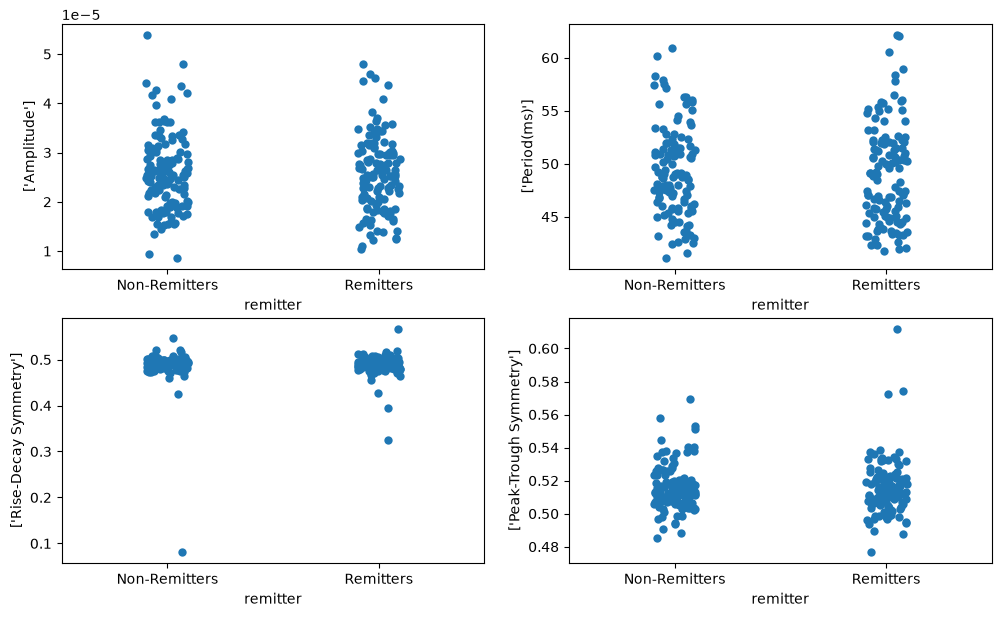

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12,7))


# amplitude
sns.stripplot(data=summary, x='remitter', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary, x='remitter', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary, x='remitter', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary, x='remitter', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

In [24]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry'}

for feat, feat_name in feature_names.items():

    x_remitter = summary[summary['remitter'] == 1][feat].dropna()
    x_non_remitter = summary[summary['remitter'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_remitter, x_non_remitter)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

Amplitude            difference between groups, U= 7377, p=0.82099
Period (ms)          difference between groups, U= 7142, p=0.51571
Rise-Decay Symmetry  difference between groups, U= 7004, p=0.36877
Peak-Trough Symmetry difference between groups, U= 7360, p=0.79724


In [25]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry'}

for feat, feat_name in feature_names.items():

    x_remitter = summary[summary['remitter'] == 1][feat].dropna()
    x_non_remitter = summary[summary['remitter'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_remitter, x_non_remitter)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

/tmp/ipykernel_4139118/1804060160.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Responder', 'Responder'])
/tmp/ipykernel_4139118/1804060160.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Responder', 'Responder'])
/tmp/ipykernel_4139118/1804060160.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Responder', 'Responder'])
/tmp/ipykernel_4139118/1804060160.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled

Text(0, 0.5, "['Peak-Trough Symmetry']")

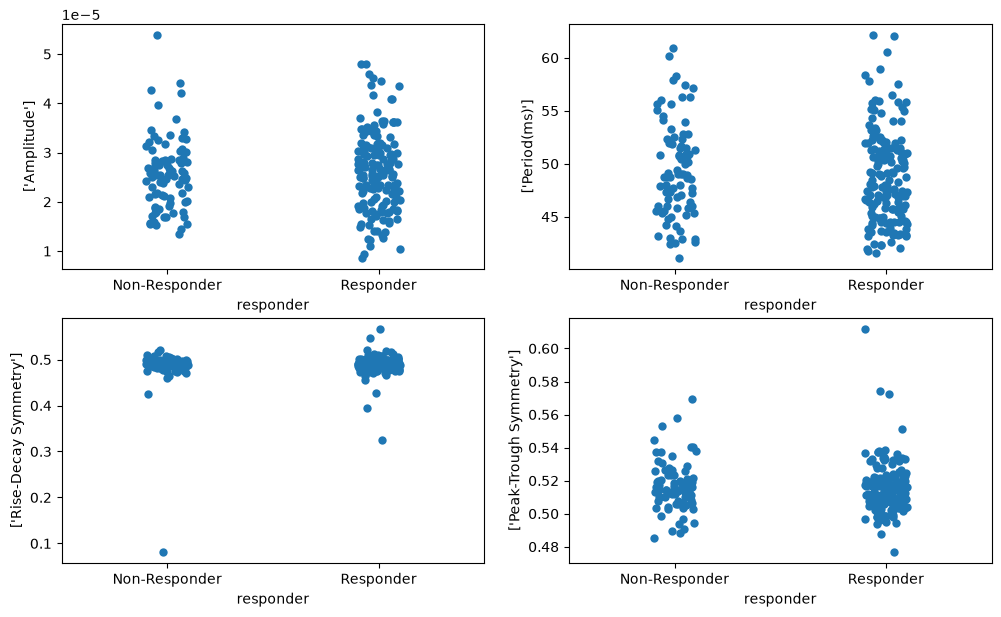

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12,7))

# amplitude
sns.stripplot(data=summary, x='responder', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Responder', 'Responder'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary, x='responder', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Responder', 'Responder'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary, x='responder', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Responder', 'Responder'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary, x='responder', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Responder', 'Responder'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

In [27]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry'}

for feat, feat_name in feature_names.items():

    x_responder = summary[summary['responder'] == 1][feat].dropna()
    x_non_responder = summary[summary['responder'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_responder, x_non_responder)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

Amplitude            difference between groups, U= 7196, p=0.45384
Period (ms)          difference between groups, U= 6304, p=0.34803
Rise-Decay Symmetry  difference between groups, U= 6569, p=0.66244
Peak-Trough Symmetry difference between groups, U= 6233, p=0.28332


In [28]:
n1, n2 = len(x_responder), len(x_non_responder)
print (n1, n2)

160 85


In [29]:
# # eyes open data 
# from bycycle import BycycleGroup
# from joblib import Parallel, delayed
# from tqdm import tqdm

# f_alpha = (8, 12)

# def process_subject_eo(subj):
#     data = eo_data[subj]
#     out = []
#     for epoch in range(data.shape[0]):
#         bg = BycycleGroup()
#         bg.fit(data[epoch], fs, f_alpha, n_jobs=1)   # was 16; parallelism is now across subjects
#         for ch in range(data.shape[1]):
#             df = bg.df_features[ch].copy()
#             df['subject_id'] = subj
#             df['epoch'] = epoch
#             df['channel'] = ch
#             df['remitter'] = labels.loc[subj, 'Remitter']
#             df['responder'] = labels.loc[subj, 'Responder']
#             out.append(df)
#     return out

# results_eo = Parallel(n_jobs=16)(delayed(process_subject_eo)(s) for s in tqdm(found_eo))

# all_cycles_eo = [d for r in results_eo for d in r]
# df_cycles_eo = pd.concat(all_cycles_eo, ignore_index=True)


# df_cycles_eo.to_pickle('df_cycles_eo.pkl')
# print(df_cycles_eo['subject_id'].nunique(), len(found_eo))

In [30]:
df_cycles_eo = pd.read_pickle('df_cycles_eo.pkl')
print(df_cycles_eo['subject_id'].nunique(), len(found_eo))

df_cycles_eo['freq'] = fs / df_cycles_eo['period']
df_bursts_eo = df_cycles_eo[df_cycles_eo['is_burst']]

df_cycles = pd.read_pickle('df_cycles_ec.pkl')


249 249


In [31]:
# possibly change to median because not as influenced by outliers 
summary_eo = df_bursts_eo.groupby('subject_id')[['volt_amp', 'period', 'freq', 'time_rdsym', 'time_ptsym']].mean()
summary_eo['burst_frac'] = df_cycles_eo.groupby('subject_id')['is_burst'].mean()


# go back to understand this code 
summary_eo['remitter'] = labels.loc[summary_eo.index, 'Remitter']
summary_eo['responder'] = labels.loc[summary_eo.index, 'Responder']

print(summary_eo)

              volt_amp     period       freq  time_rdsym  time_ptsym  \
subject_id                                                             
sub-87999321  0.000021  47.304196  10.975046    0.492148    0.522697   
sub-88000181  0.000021  46.197802  11.272112    0.488732    0.497206   
sub-88000313  0.000027  47.508340  10.865920    0.488418    0.506909   
sub-88000489  0.000029  55.017253   9.382652    0.492950    0.517615   
sub-88001661  0.000015  41.170543  12.687596    0.453727    0.496257   
...                ...        ...        ...         ...         ...   
sub-88076401  0.000016  41.823529  12.497199    0.458438    0.514178   
sub-88076445  0.000022  43.710889  11.988014    0.491547    0.501776   
sub-88076849  0.000023  45.996960  11.325786    0.514394    0.512518   
sub-88077525  0.000011  52.666667   9.614930    0.470383    0.488147   
sub-88077569  0.000015  40.922330  12.410958    0.476799    0.520325   

              burst_frac  remitter  responder  
subject_id     

In [32]:
# remitter/non-remitter comparison 
remitters = summary_eo[summary_eo['remitter'] == 1]
non_remitters = summary_eo[summary_eo['remitter'] == 0]

features_keep = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym']

print(summary_eo[features_keep].head())
print(df_cycles_eo.shape)
print(df_cycles_eo['subject_id'].value_counts())

              volt_amp     period  time_rdsym  time_ptsym
subject_id                                               
sub-87999321  0.000021  47.304196    0.492148    0.522697
sub-88000181  0.000021  46.197802    0.488732    0.497206
sub-88000313  0.000027  47.508340    0.488418    0.506909
sub-88000489  0.000029  55.017253    0.492950    0.517615
sub-88001661  0.000015  41.170543    0.453727    0.496257
(5129965, 30)
subject_id
sub-88012461    23766
sub-88049761    23720
sub-88050713    23654
sub-88070105    23606
sub-88025325    23513
                ...  
sub-88065425    11402
sub-88063713    11074
sub-88066457    10722
sub-88021365    10024
sub-88064477     8854
Name: count, Length: 249, dtype: int64


/tmp/ipykernel_4139118/3236634291.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/3236634291.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/3236634291.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/3236634291.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled

Text(0, 0.5, "['Peak-Trough Symmetry']")

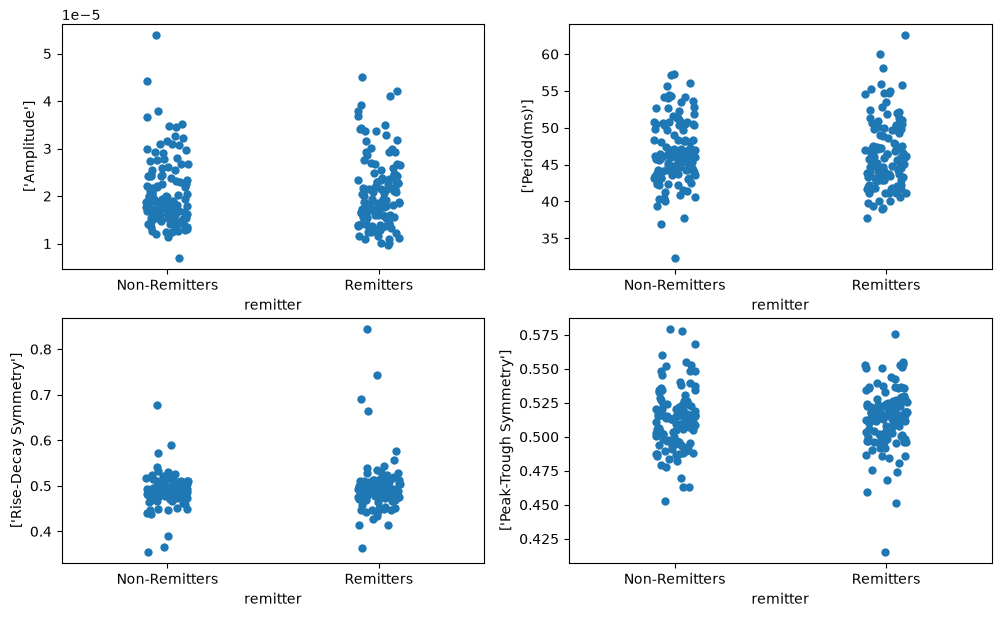

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12,7))

# amplitude
sns.stripplot(data=summary_eo, x='remitter', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary_eo, x='remitter', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary_eo, x='remitter', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary_eo, x='remitter', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

In [34]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry'}

for feat, feat_name in feature_names.items():

    x_remitter = summary_eo[summary_eo['remitter'] == 1][feat].dropna()
    x_non_remitter = summary_eo[summary_eo['remitter'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_remitter, x_non_remitter)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

Amplitude            difference between groups, U= 7353, p=0.85989
Period (ms)          difference between groups, U= 6931, p=0.54741
Rise-Decay Symmetry  difference between groups, U= 7566, p=0.56853
Peak-Trough Symmetry difference between groups, U= 7812, p=0.30540


In [35]:
n1 = len(x_remitter)
n2 = len(x_non_remitter)
print(n1, n2)

118 123


In [36]:
# responder/non-responder comparison
responders = summary_eo[summary_eo['responder'] == 1]
non_responders = summary_eo[summary_eo['responder'] == 0] 

features_keep = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym']

In [37]:
features = ['volt_amp', 'period', 'freq', 'time_rdsym', 'time_ptsym', 'burst_frac']
print(summary_eo[features].dtypes)
print(summary_eo[features].isna().sum())
print(summary_eo.columns.tolist())

volt_amp      float64
period        float64
freq          float64
time_rdsym    float64
time_ptsym    float64
burst_frac    float64
dtype: object
volt_amp      0
period        0
freq          0
time_rdsym    0
time_ptsym    0
burst_frac    0
dtype: int64
['volt_amp', 'period', 'freq', 'time_rdsym', 'time_ptsym', 'burst_frac', 'remitter', 'responder']


/tmp/ipykernel_4139118/3737312565.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Responders', 'Responders'])
/tmp/ipykernel_4139118/3737312565.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Responders', 'Responders'])
/tmp/ipykernel_4139118/3737312565.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Responders', 'Responders'])
/tmp/ipykernel_4139118/3737312565.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be misl

Text(0, 0.5, "['Peak-Trough Symmetry']")

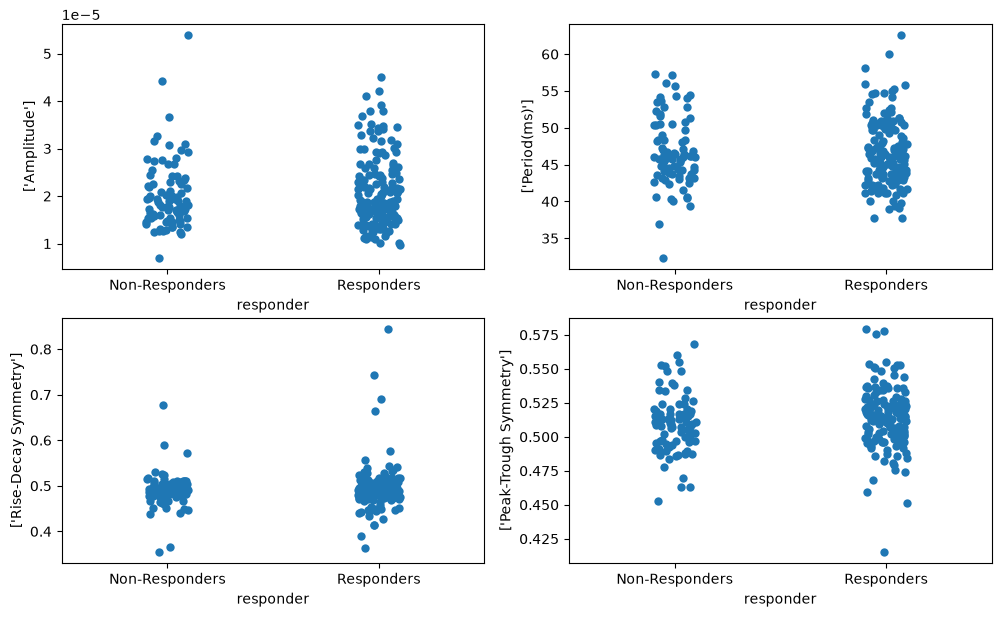

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(12,7))

# amplitude
sns.stripplot(data=summary_eo, x='responder', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Responders', 'Responders'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary_eo, x='responder', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Responders', 'Responders'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary_eo, x='responder', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Responders', 'Responders'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary_eo, x='responder', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Responders', 'Responders'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

In [39]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry'}

for feat, feat_name in feature_names.items():

    x_responder = summary_eo[summary_eo['responder'] == 1][feat].dropna()
    x_non_responder = summary_eo[summary_eo['responder'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_responder, x_non_responder)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))

Amplitude            difference between groups, U= 7135, p=0.36518
Period (ms)          difference between groups, U= 6602, p=0.90482
Rise-Decay Symmetry  difference between groups, U= 6851, p=0.72051
Peak-Trough Symmetry difference between groups, U= 7722, p=0.04158


In [40]:
n1, n2 = len(x_responder), len(x_non_responder)
print (n1, n2)

155 86


In [41]:
# possibly change to median because not as influenced by outliers 
summary_med = df_bursts.groupby('subject_id')[['volt_amp', 'period', 'freq', 'time_rdsym', 'time_ptsym']].median()
summary_med['burst_frac'] = df_cycles.groupby('subject_id')['is_burst'].mean() # stays a mean bc otherwise burst_frac will be 0 for all subjects 


# go back to understand this code 
summary_med['remitter'] = labels.loc[summary_med.index, 'Remitter']
summary_med['responder'] = labels.loc[summary_med.index, 'Responder']

print(summary_med)

              volt_amp  period       freq  time_rdsym  time_ptsym  burst_frac  \
subject_id                                                                      
sub-87999321  0.000023    51.0   9.803922    0.491377    0.519231    0.055342   
sub-88000181  0.000030    47.0  10.638298    0.500000    0.519231    0.036933   
sub-88000313  0.000026    50.0  10.000000    0.500000    0.511628    0.201139   
sub-88000489  0.000030    55.0   9.090909    0.491803    0.516129    0.188201   
sub-88000533  0.000024    46.0  10.869565    0.510204    0.581395    0.007701   
...                ...     ...        ...         ...         ...         ...   
sub-88076401  0.000021    52.0   9.615385    0.503968    0.500000    0.015272   
sub-88076445  0.000024    44.0  11.363636    0.476732    0.516129    0.170717   
sub-88076849  0.000019    46.0  10.869565    0.490196    0.518188    0.112566   
sub-88077525  0.000009    45.5  10.990338    0.590036    0.505556    0.001560   
sub-88077569  0.000018    43

In [42]:
# remitter/non-remitter comparison 
remitters = summary_med[summary_med['remitter'] == 1]
non_remitters = summary_med[summary_med['remitter'] == 0]

features_keep = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym']

print(summary_med[features_keep].head())
print(df_cycles.shape)
print(df_cycles['subject_id'].value_counts())

              volt_amp  period  time_rdsym  time_ptsym
subject_id                                            
sub-87999321  0.000023    51.0    0.491377    0.519231
sub-88000181  0.000030    47.0    0.500000    0.519231
sub-88000313  0.000026    50.0    0.500000    0.511628
sub-88000489  0.000030    55.0    0.491803    0.516129
sub-88000533  0.000024    46.0    0.510204    0.581395
(5298044, 30)
subject_id
sub-88059081    43932
sub-88059169    40126
sub-88059261    25393
sub-88077569    24229
sub-88005941    23965
                ...  
sub-88035589    16943
sub-88068885    16685
sub-88044189    15563
sub-88032753    15524
sub-88063713    12557
Name: count, Length: 249, dtype: int64


/tmp/ipykernel_4139118/3215114886.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/3215114886.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/3215114886.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
/tmp/ipykernel_4139118/3215114886.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled

Text(0, 0.5, "['Peak-Trough Symmetry']")

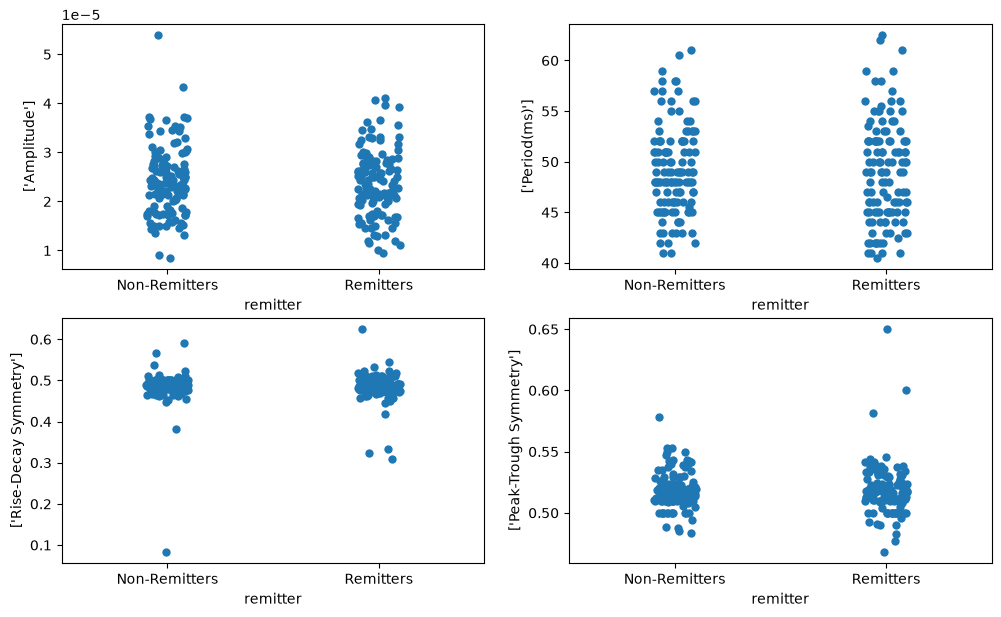

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12,7))


# amplitude
sns.stripplot(data=summary_med, x='remitter', y='volt_amp', ax=axes[0][0], size=6, jitter=True)
axes[0][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][0].set_ylabel(['Amplitude'])

# period
sns.stripplot(data=summary_med, x='remitter', y='period', ax=axes[0][1], size=6, jitter=True)
axes[0][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[0][1].set_ylabel(['Period(ms)'])

# time_rdsym
sns.stripplot(data=summary_med, x='remitter', y='time_rdsym', ax=axes[1][0], size=6, jitter=True)
axes[1][0].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][0].set_ylabel(['Rise-Decay Symmetry'])

#time_ptsym
sns.stripplot(data=summary_med, x='remitter', y='time_ptsym', ax=axes[1][1], size=6, jitter=True)
axes[1][1].set_xticklabels(['Non-Remitters', 'Remitters'])
axes[1][1].set_ylabel(['Peak-Trough Symmetry'])

In [44]:
# statistical analyses completed here - using mann-whitney u (assumes that 2 groups are ind. of each other and obs w/in each group are also ind.)
feature_names = {'volt_amp': 'Amplitude',
                 'period': 'Period (ms)',
                 'time_rdsym': 'Rise-Decay Symmetry',
                 'time_ptsym': 'Peak-Trough Symmetry'}

for feat, feat_name in feature_names.items():

    x_remitter = summary_med[summary_med['remitter'] == 1][feat].dropna()
    x_non_remitter = summary_med[summary_med['remitter'] == 0][feat].dropna()
    ustat, pval = stats.mannwhitneyu(x_remitter, x_non_remitter)
    print('{:20s} difference between groups, U= {:3.0f}, p={:.5f}'.format(feat_name, ustat, pval))


Amplitude            difference between groups, U= 7381, p=0.82660
Period (ms)          difference between groups, U= 7233, p=0.62626
Rise-Decay Symmetry  difference between groups, U= 7262, p=0.66395
Peak-Trough Symmetry difference between groups, U= 7378, p=0.82225


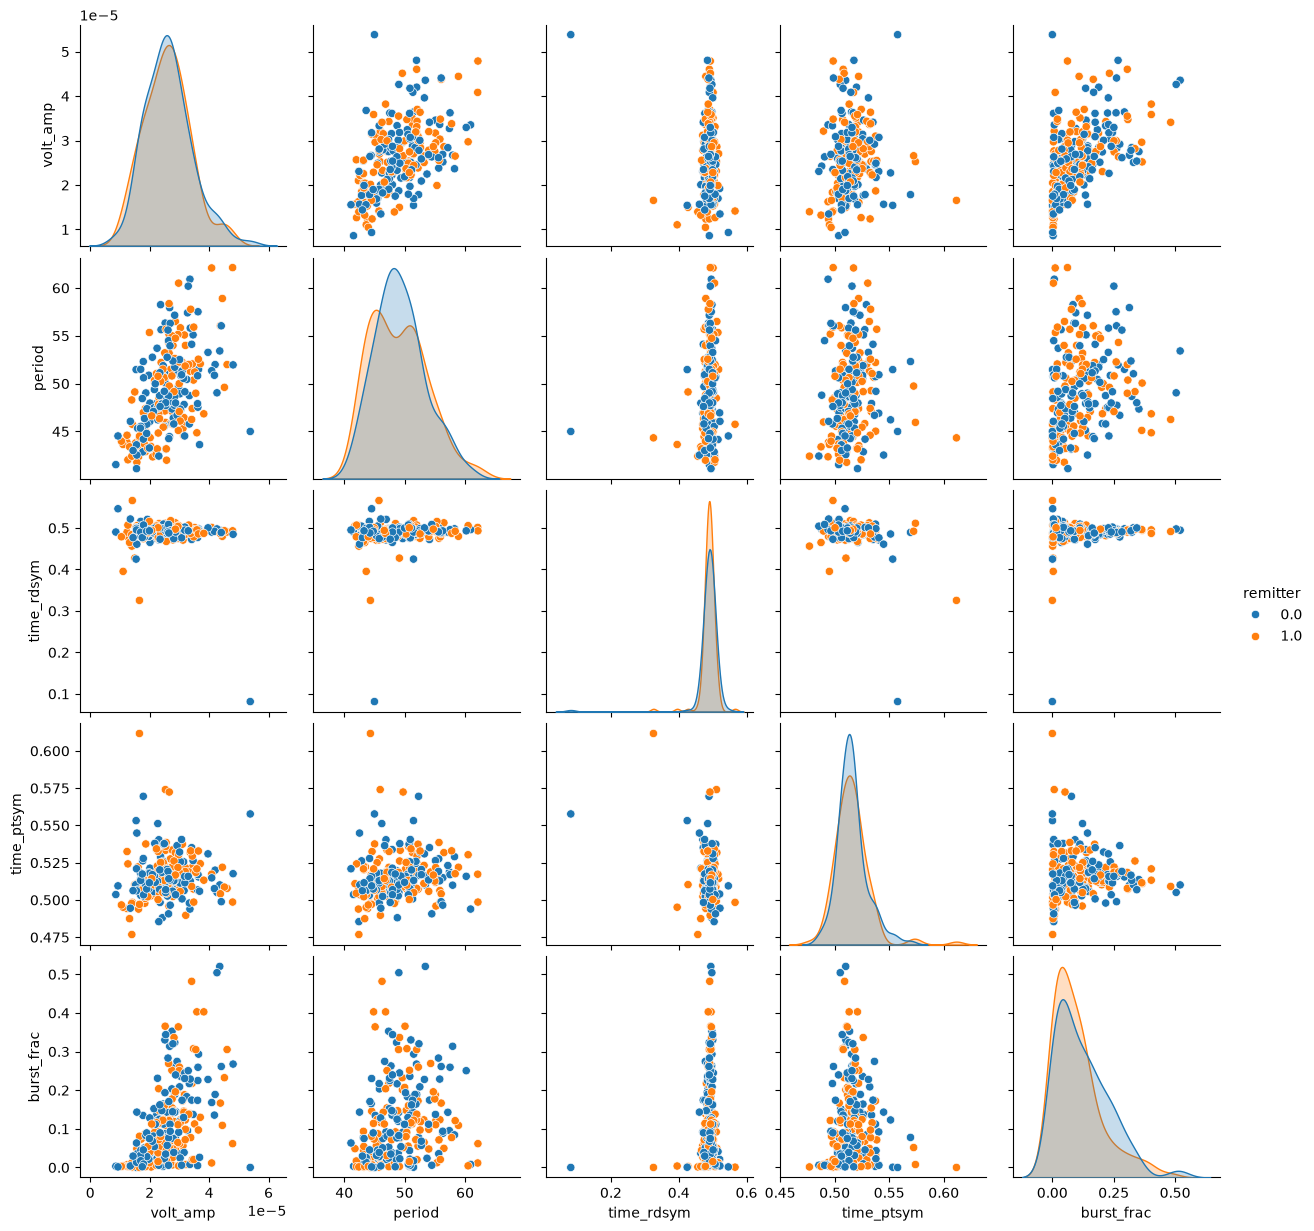

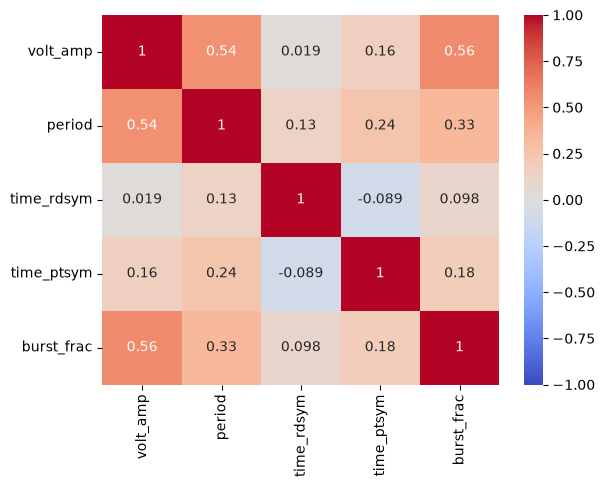

In [45]:
import matplotlib.pyplot as plt 
import seaborn as sns

features = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'burst_frac']

plot_data = summary[features + ['remitter']].dropna() # smaller data built but no comparison happening here (happens through parameter, hue)

sns.pairplot(plot_data, hue='remitter')
plt.show()

corr = plot_data[features].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

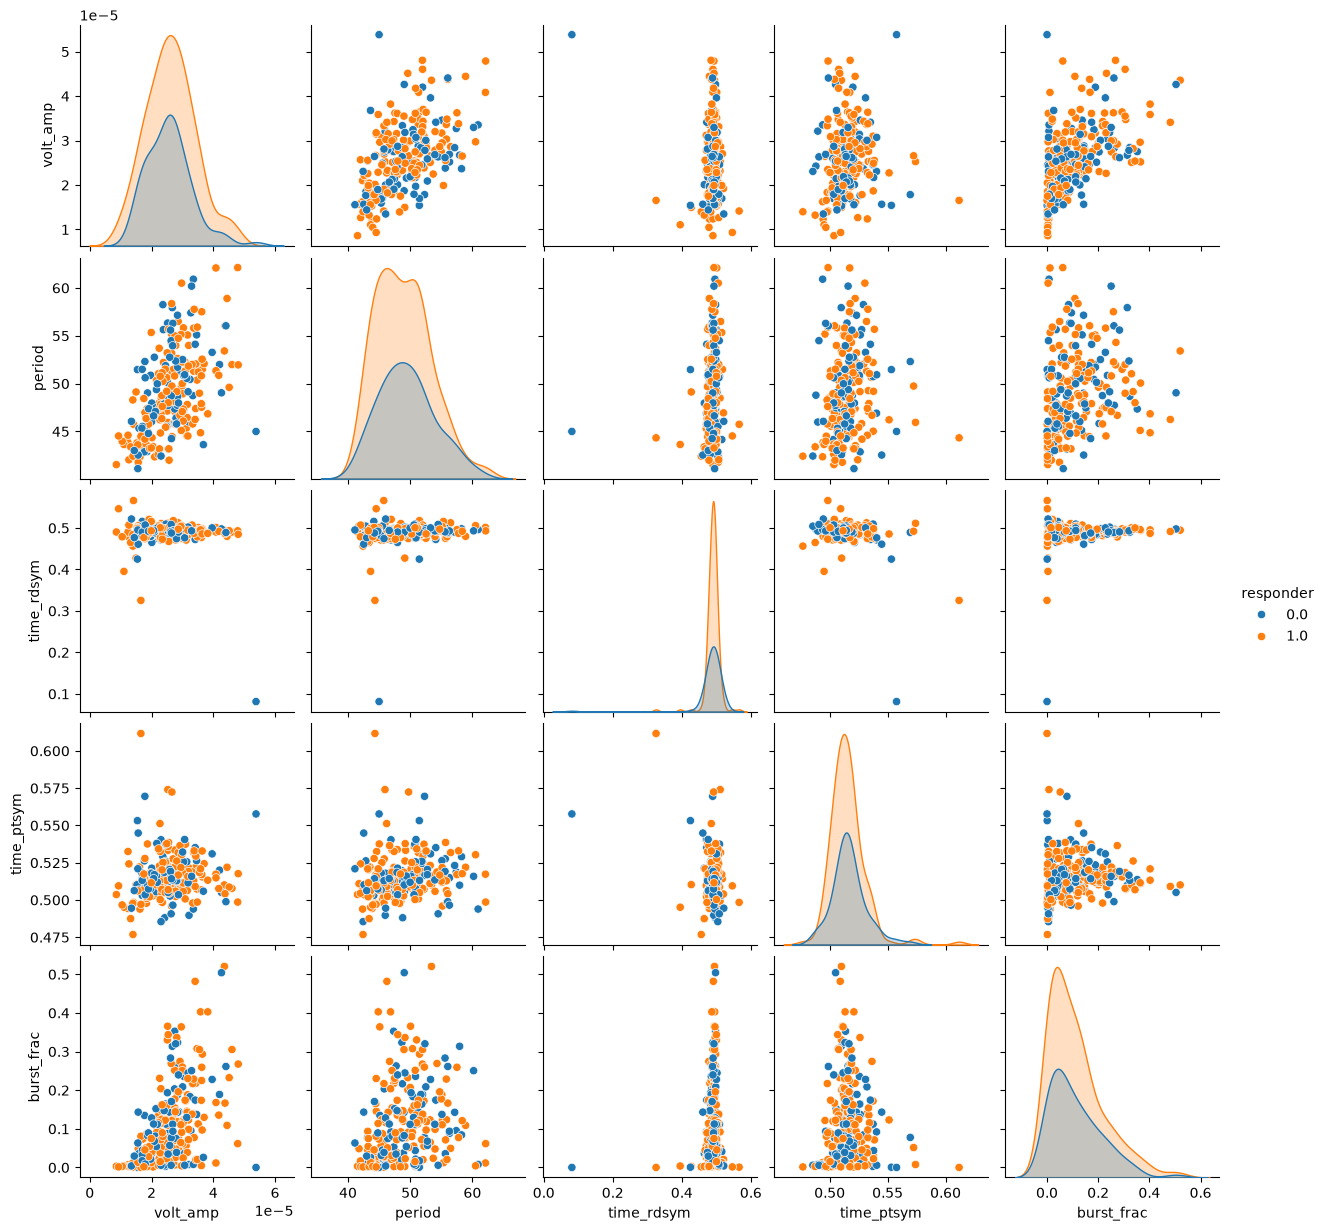

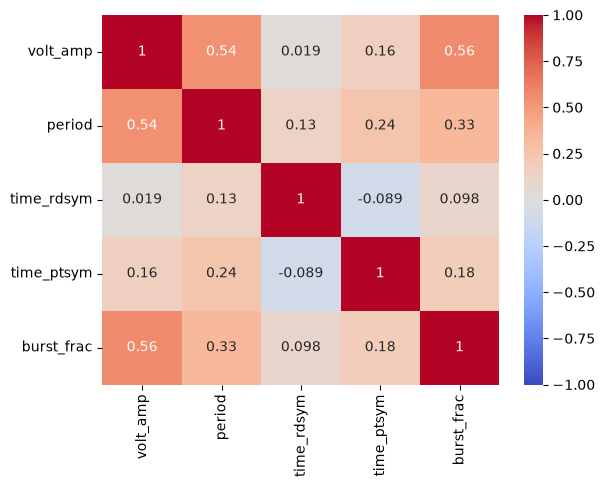

In [46]:
features = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'burst_frac']

plot_data = summary[features + ['responder']].dropna() # smaller data built but no comparison happening here (happens through parameter, hue)

sns.pairplot(plot_data, hue='responder')
plt.show()

corr = plot_data[features].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

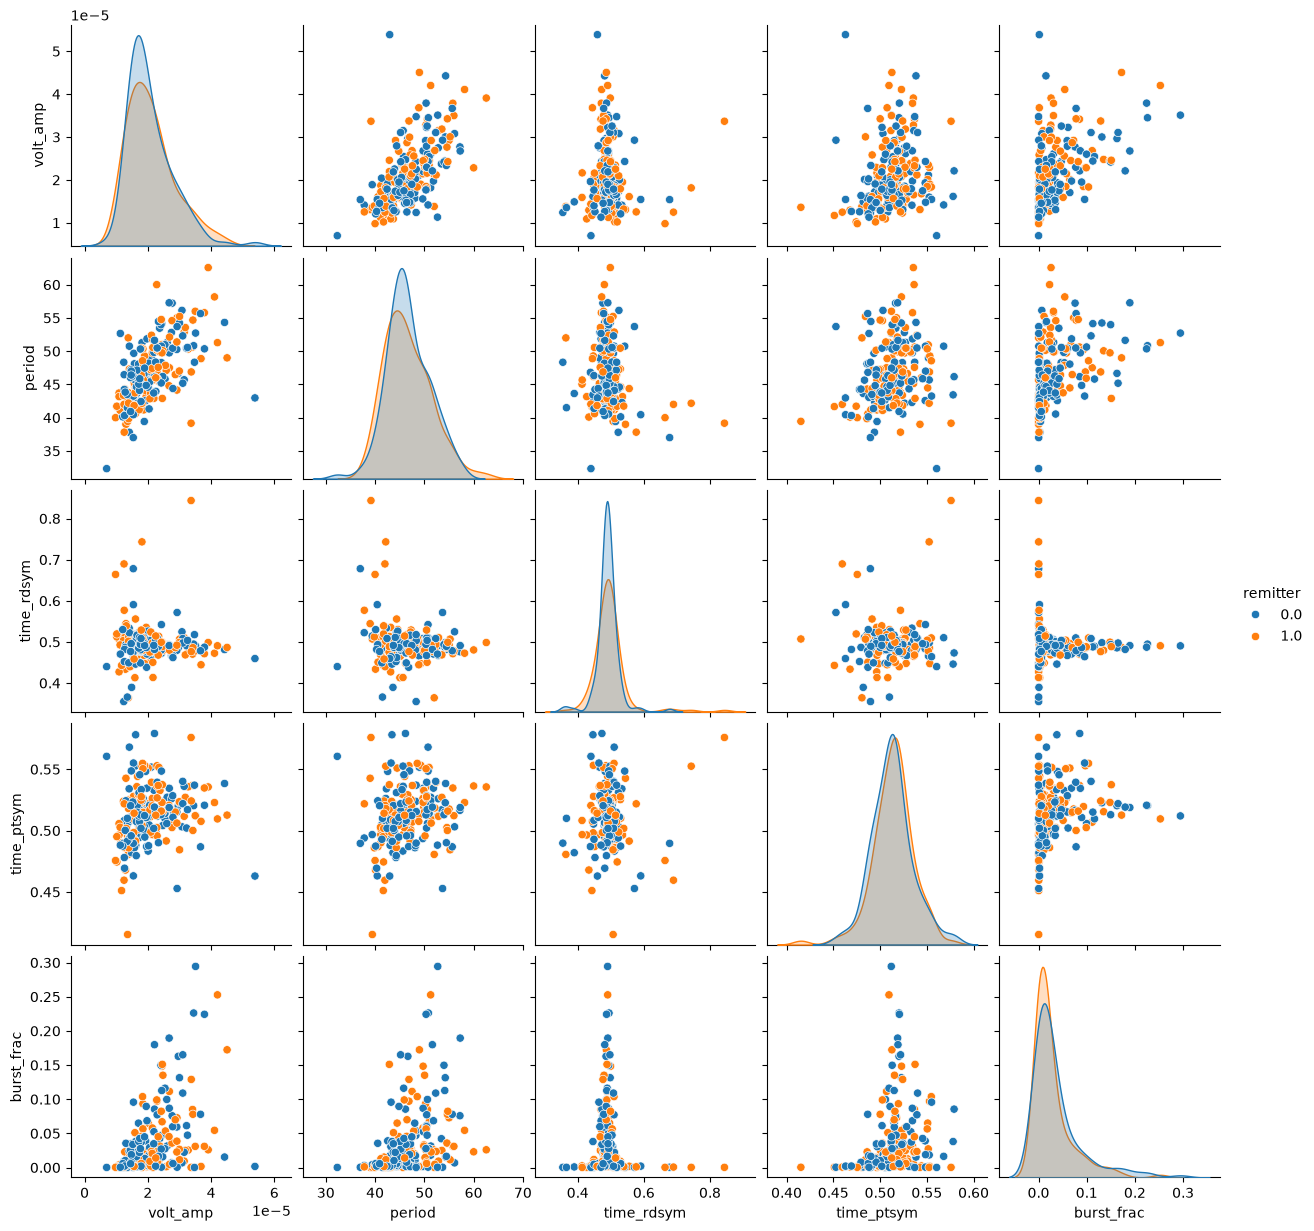

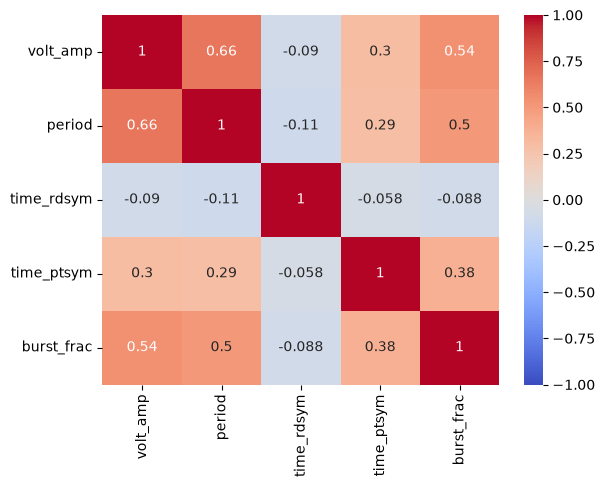

In [47]:
features = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'burst_frac']

plot_data = summary_eo[features + ['remitter']].dropna() # smaller data built but no comparison happening here (happens through parameter, hue)

sns.pairplot(plot_data, hue='remitter')
plt.show()

corr = plot_data[features].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

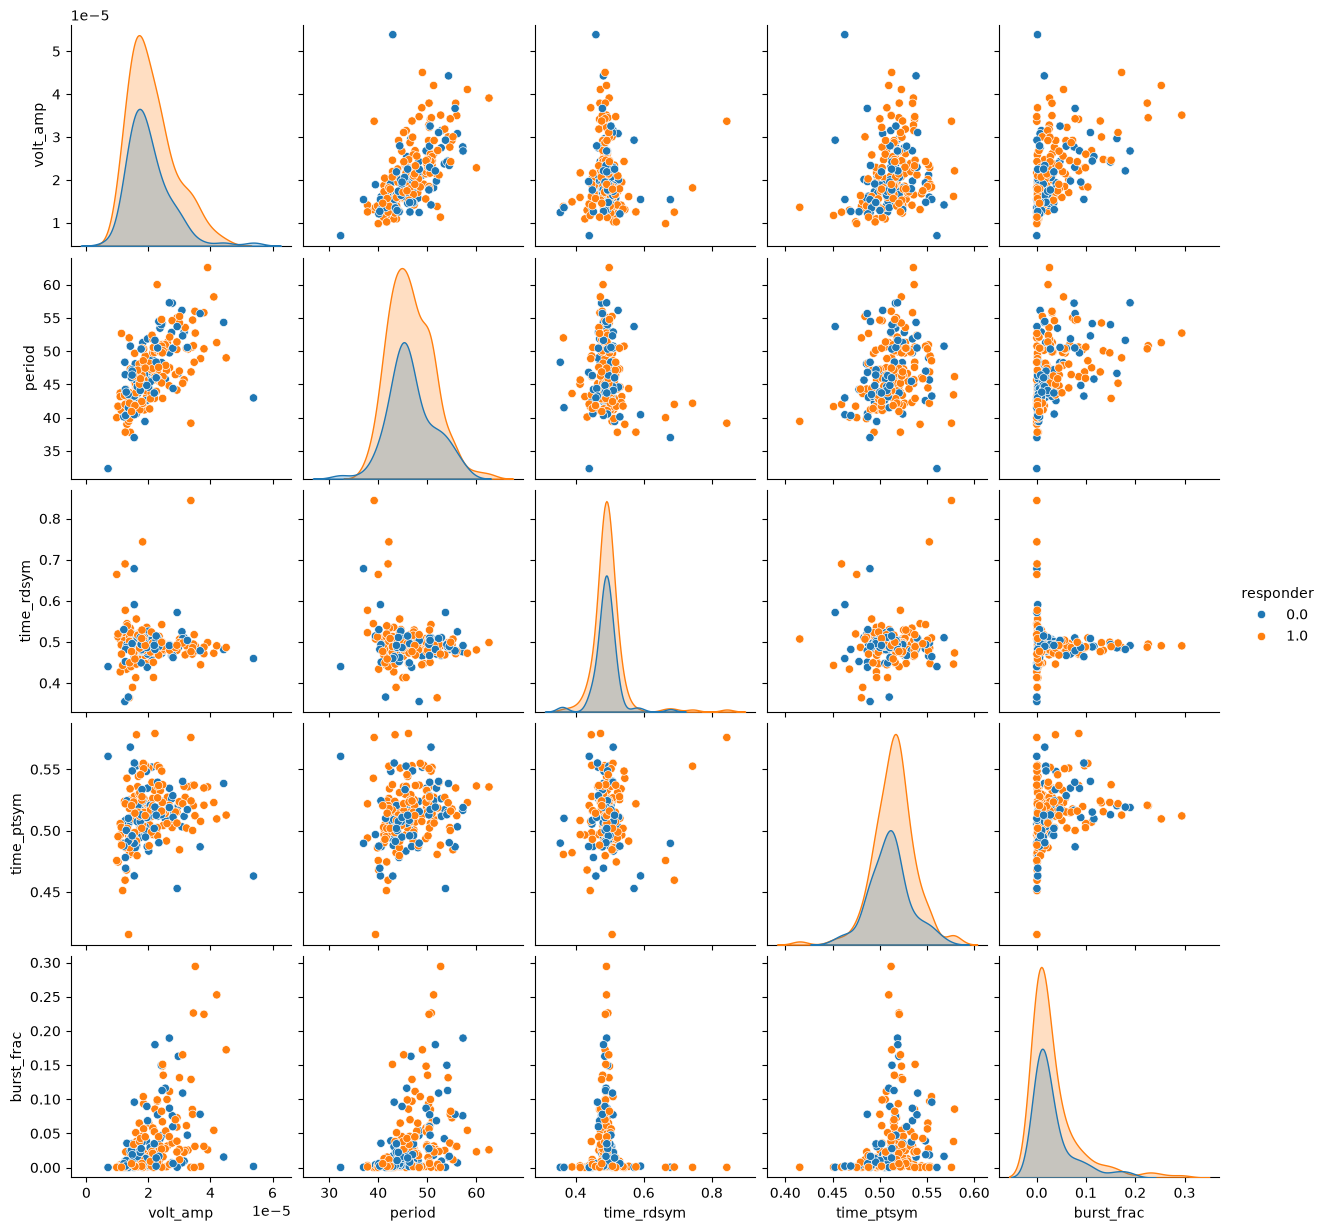

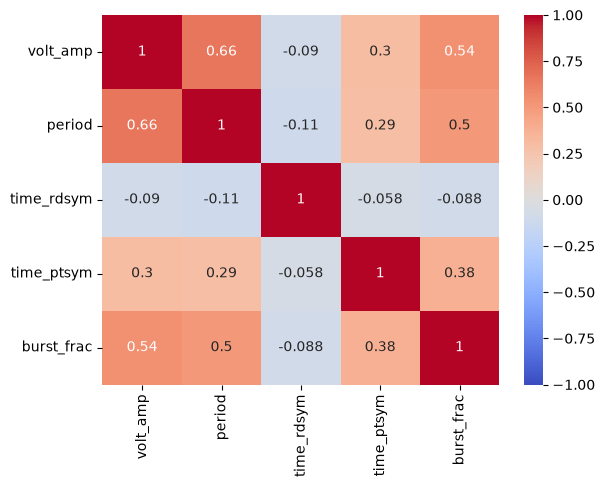

In [48]:
features = ['volt_amp', 'period', 'time_rdsym', 'time_ptsym', 'burst_frac']

plot_data = summary_eo[features + ['responder']].dropna() # smaller data built but no comparison happening here (happens through parameter, hue)

sns.pairplot(plot_data, hue='responder')
plt.show()

corr = plot_data[features].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

In [49]:
# looking at age and BDI-pre 
has_BDI_pre = meta[meta['BDI_pre'].notna()].copy()
print(len(has_BDI_pre), 'subjects with a BDI-pre value')
print(has_BDI_pre['BDI_pre'].value_counts())

243 subjects with a BDI-pre value
BDI_pre
26.0    14
35.0    14
21.0    12
37.0    12
22.0    11
29.0    10
31.0    10
20.0     9
16.0     9
30.0     9
23.0     9
36.0     7
28.0     7
41.0     7
33.0     6
18.0     6
17.0     6
40.0     6
32.0     6
45.0     5
34.0     5
43.0     4
38.0     4
8.0      4
25.0     4
42.0     3
55.0     3
52.0     3
14.0     3
44.0     3
24.0     3
19.0     3
2.0      3
39.0     3
47.0     2
15.0     2
27.0     2
4.0      2
49.0     1
48.0     1
56.0     1
50.0     1
0.0      1
51.0     1
9.0      1
10.0     1
58.0     1
1.0      1
53.0     1
13.0     1
Name: count, dtype: int64


In [50]:
has_age = meta[meta['age'].notna()].copy()
print(len(has_age), 'subjects with an age value')
print(has_age['age'].value_counts())

1362 subjects with an age value
age
21.00    5
22.00    4
28.09    4
9.00     4
23.04    3
        ..
62.12    1
29.11    1
49.61    1
24.63    1
42.37    1
Name: count, Length: 1199, dtype: int64


In [51]:
# adding age and bdi_pre to summary 
labels = has_remit.drop_duplicates(subset='TDBRAIN_ID').set_index('TDBRAIN_ID')


summary['age'] = labels.loc[summary.index, 'age']
summary['bdi_pre'] = labels.loc[summary.index, 'BDI_pre']

print(summary.columns.tolist())
print(summary.head())

['volt_amp', 'period', 'freq', 'time_rdsym', 'time_ptsym', 'burst_frac', 'remitter', 'responder', 'age', 'bdi_pre']
              volt_amp     period       freq  time_rdsym  time_ptsym  \
subject_id                                                             
sub-87999321  0.000024  50.580214  10.155937    0.495490    0.515169   
sub-88000181  0.000030  47.281796  10.825160    0.498454    0.518379   
sub-88000313  0.000029  49.625812  10.372711    0.494780    0.510216   
sub-88000489  0.000032  55.086246   9.290944    0.494386    0.511861   
sub-88000533  0.000025  45.948571  10.994598    0.511266    0.574036   

              burst_frac  remitter  responder    age  bdi_pre  
subject_id                                                     
sub-87999321    0.055342       1.0        1.0  49.66     20.0  
sub-88000181    0.036933       0.0        0.0  45.99     47.0  
sub-88000313    0.201139       1.0        1.0  35.38     21.0  
sub-88000489    0.188201       1.0        1.0  42.36     21

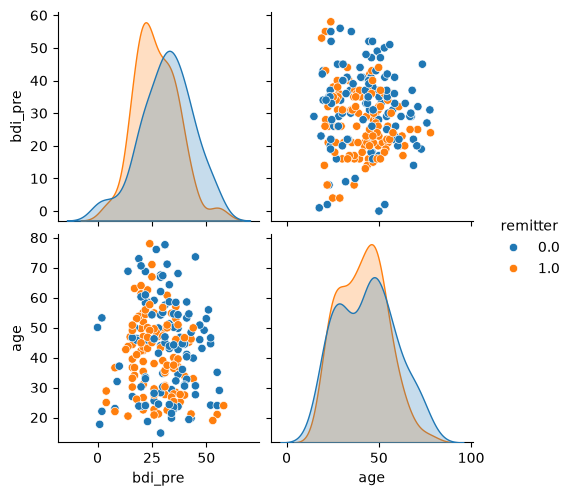

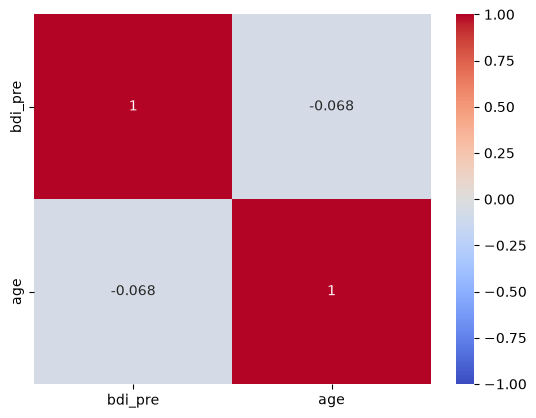

In [52]:
features = ['bdi_pre', 'age']

plot_data = summary[features + ['remitter']].dropna() # smaller data built but no comparison happening here (happens through parameter, hue)

sns.pairplot(plot_data, hue='remitter')
plt.show()

corr = plot_data[features].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

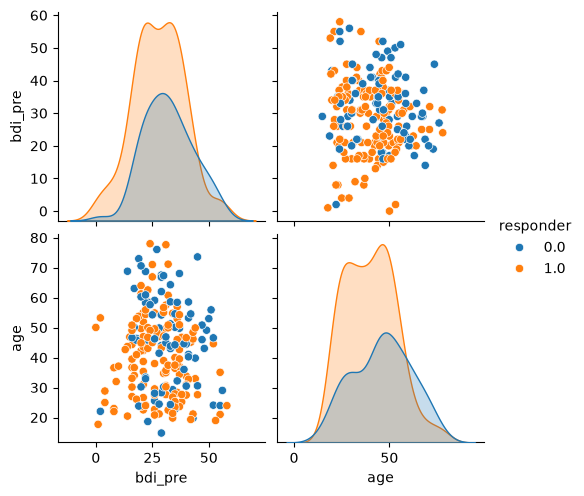

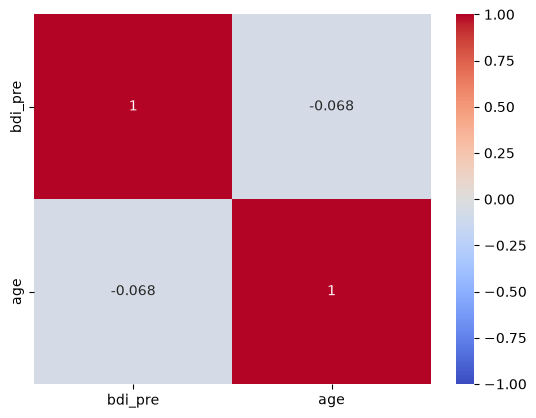

In [53]:
features = ['bdi_pre', 'age']

plot_data = summary[features + ['responder']].dropna() # smaller data built but no comparison happening here (happens through parameter, hue)

sns.pairplot(plot_data, hue='responder')
plt.show()

corr = plot_data[features].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

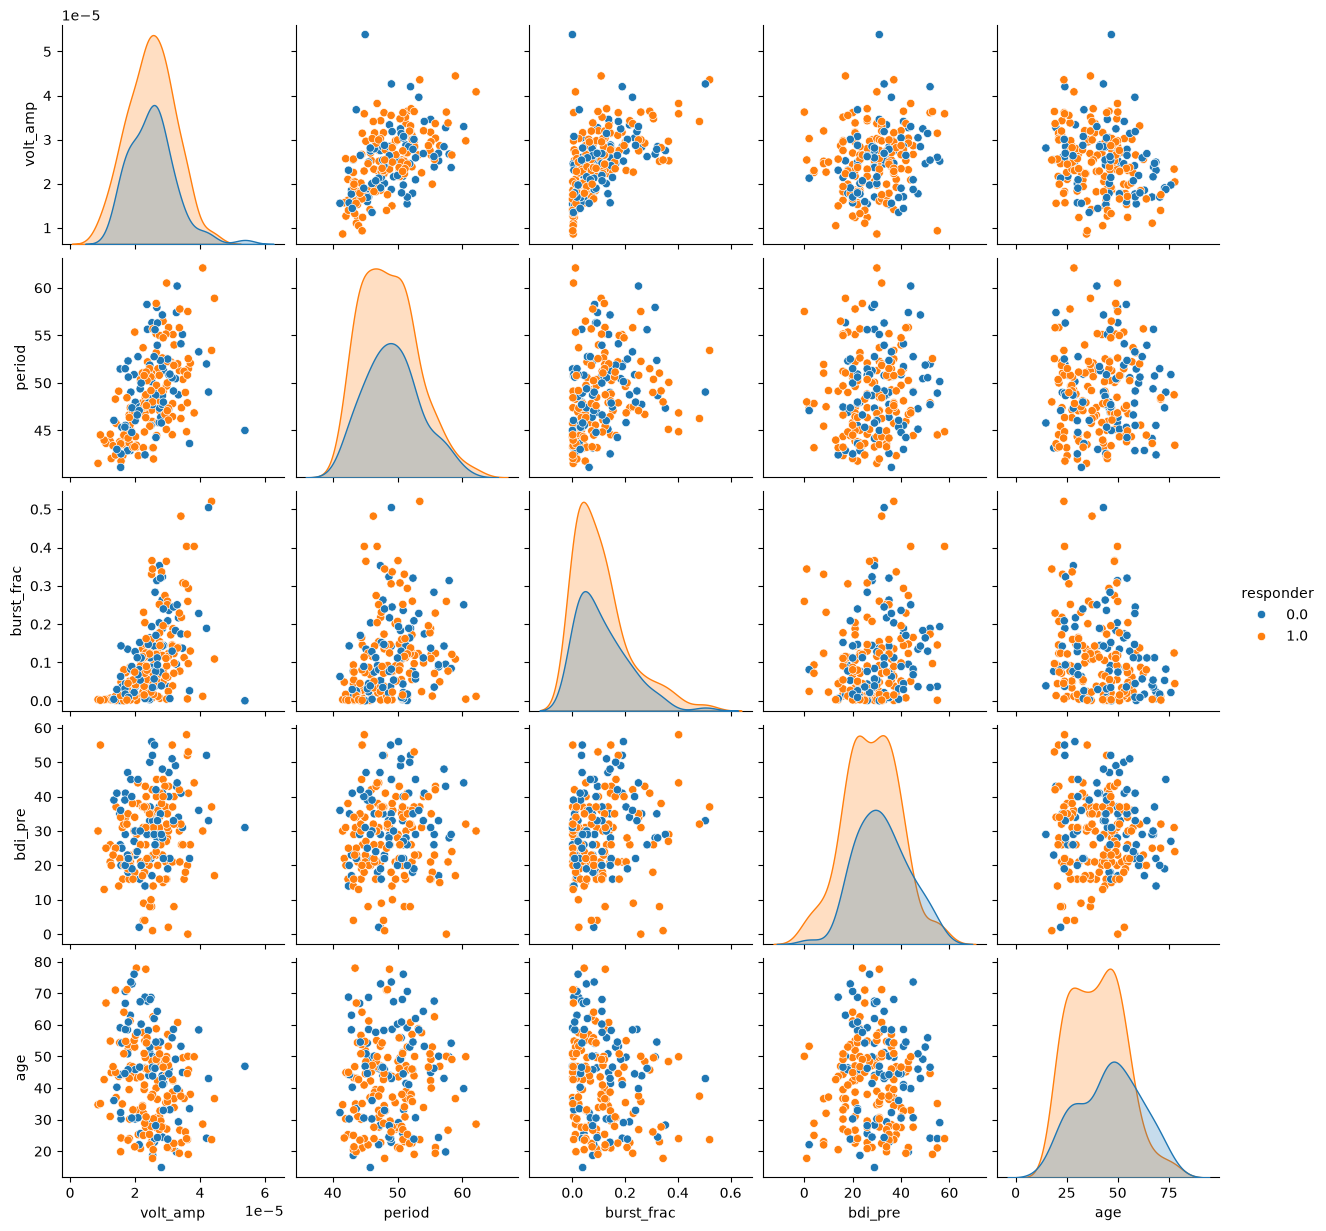

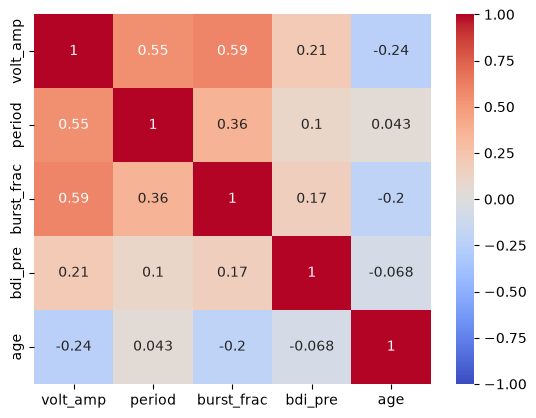

In [ ]:
features = ['volt_amp', 'period', 'burst_frac', 'bdi_pre', 'age']

plot_data = summary[features + ['responder']].dropna() # smaller data built but no comparison happening here (happens through parameter, hue)

sns.pairplot(plot_data, hue='responder')
plt.show()

corr = plot_data[features].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

In [55]:
# typical BDI-pre in each group
print(summary.groupby('responder')['bdi_pre'].mean())
print(summary.groupby('responder')['bdi_pre'].median())

# how many subjects are in each group
print(summary['responder'].value_counts())

# mannwhitneyu
from scipy.stats import mannwhitneyu
yes = summary[summary['responder'] == 1]['bdi_pre'].dropna()   # responders
no = summary[summary['responder'] == 0]['bdi_pre'].dropna()    # non-responders
print(mannwhitneyu(yes, no)) # comparing responders and non-responders 

responder
0.0    31.987654
1.0    27.802920
Name: bdi_pre, dtype: float64
responder
0.0    31.0
1.0    28.0
Name: bdi_pre, dtype: float64
responder
1.0    160
0.0     85
Name: count, dtype: int64
MannwhitneyuResult(statistic=np.float64(4472.0), pvalue=np.float64(0.01673958293482696))


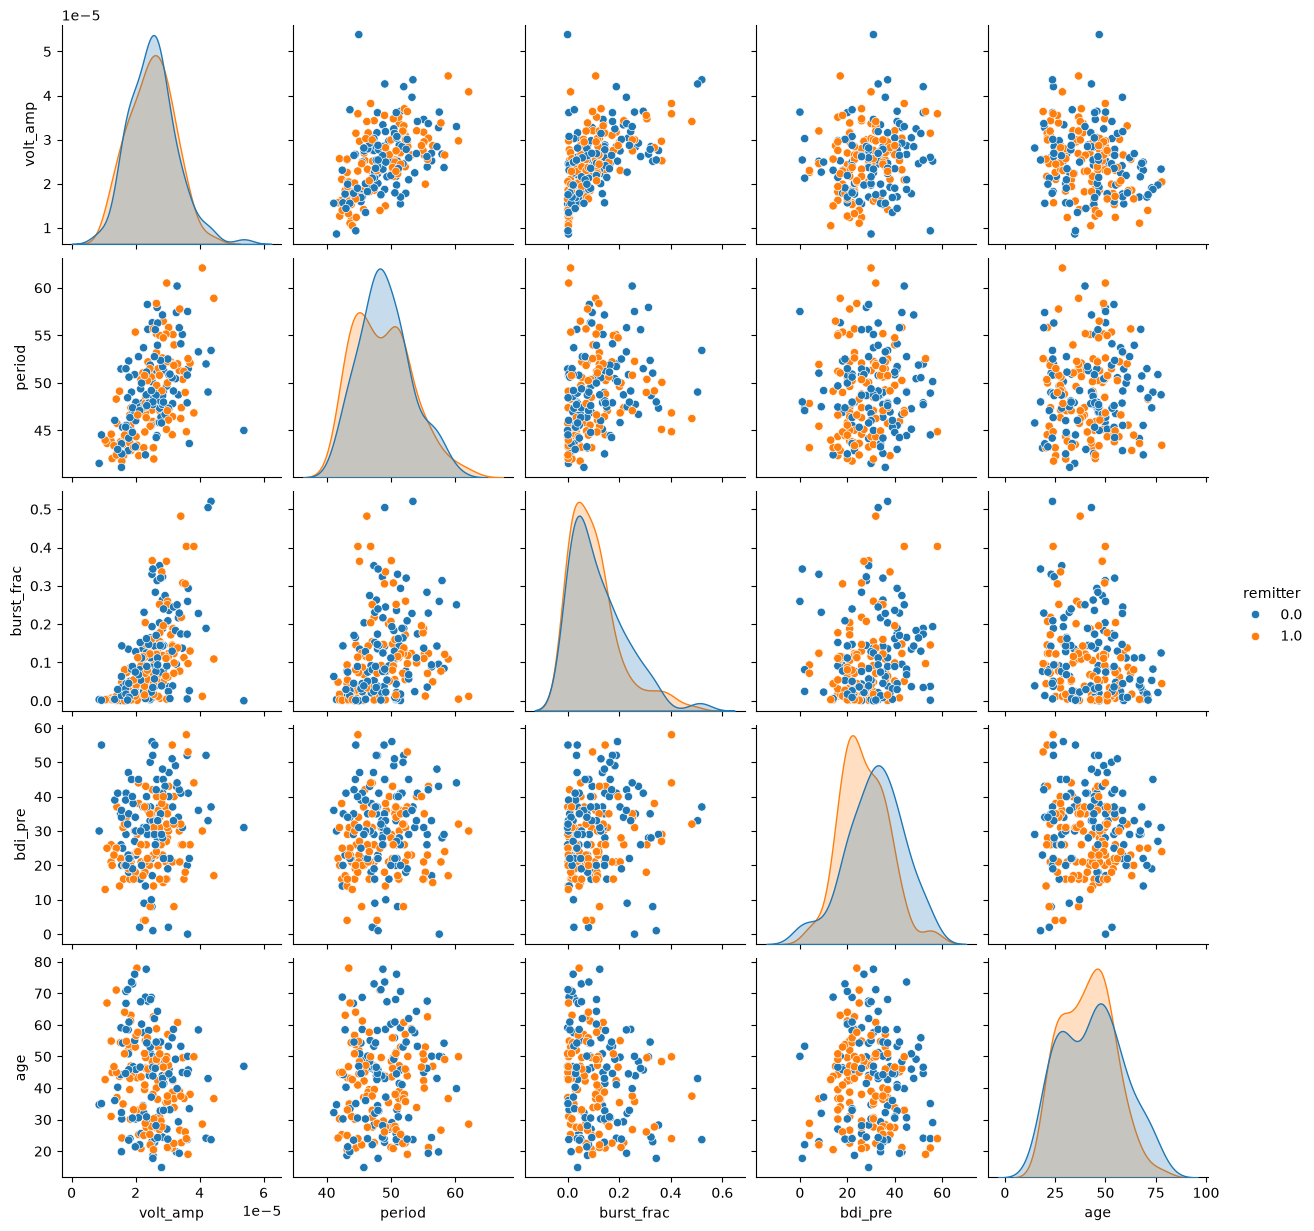

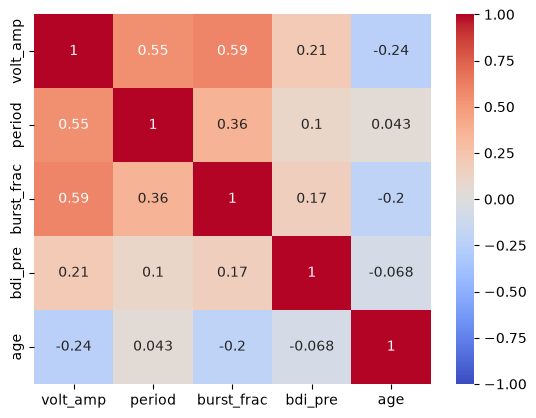

In [56]:
features = ['volt_amp', 'period', 'burst_frac', 'bdi_pre', 'age']

plot_data = summary[features + ['remitter']].dropna() # smaller data built but no comparison happening here (happens through parameter, hue)

sns.pairplot(plot_data, hue='remitter')
plt.show()

corr = plot_data[features].corr(method='spearman')
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

In [57]:
# typical BDI-pre in each group
print(summary.groupby('remitter')['bdi_pre'].median())
print(summary.groupby('remitter')['bdi_pre'].mean())

# how many subjects are in each group
print(summary['remitter'].value_counts())

# mannwhitneyu
from scipy.stats import mannwhitneyu
yes = summary[summary['remitter'] == 1]['bdi_pre'].dropna()   # remitters
no = summary[summary['remitter'] == 0]['bdi_pre'].dropna()    # non-remitters
print(mannwhitneyu(yes, no))

remitter
0.0    33.0
1.0    26.0
Name: bdi_pre, dtype: float64
remitter
0.0    31.681818
1.0    26.990741
Name: bdi_pre, dtype: float64
remitter
0.0    123
1.0    122
Name: count, dtype: int64
MannwhitneyuResult(statistic=np.float64(4335.0), pvalue=np.float64(0.000565009689251306))


In [96]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler

summary["remitter"] = (summary["remitter"] > 0).astype(int)

X_old = summary.drop(columns=["remitter", "responder"]) # independent values
X = X_old.dropna()
y_old = summary["remitter"] # dependent variables
y = y_old.dropna() 

X, y = X.align(y, join='inner', axis=0)

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.2,
    random_state=42,
    stratify=y, # makes sure the proportion of 0s and 1s remains identical among training dataset and testing dataset
)

scaler = (StandardScaler())

X_train_scaled = scaler.fit_transform(  
    X_train
)

X_test_scaled = scaler.transform(
    X_test)

base_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

param_grid = {
    "C": [      # inverse of regularization strength (technique used to prevent a ML model from over-fitting and memorizing training data too closely )
        0.01,
        0.1, 
        1.0,
        10.0,
        100.0,  # least "strict" 
    ], 

    "penalty": [
        "l2"
    ], 
    "solver": [
        "lbfgs"
    ], 
}

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid, 
    cv=5, 
    scoring="accuracy",
)

grid_search.fit(
    X_train_scaled, y_train
)

best_model = (
    grid_search.best_estimator_
)

print(
    f"Best Hyperparameters: {grid_search.best_params_}\n"
)

y_pred = best_model.predict(
    X_test_scaled
)

y_prob = best_model.predict_proba(X_test_scaled)[
    :, 1
]

accuracy = accuracy_score(
    y_test, y_pred
)

roc_auc = roc_auc_score(
    y_test, y_prob
)

nppv_score = nppv(
    y_test, y_pred
)

conf_matrix = confusion_matrix(
    y_test, y_pred
)

class_report = classification_report(
    y_test, y_pred
)

print(
    f"Test Accuracy: {accuracy:.4f}"
)  # Prints formatted accuracy value representing percentage of accurate model classifications.

print(
    f"ROC-AUC Score: {roc_auc:.4f}\n"
)  # Prints the Area Under the Curve parameter measuring overall class discrimination strength.

print(
    "Confusion Matrix:"
)  # Outputs descriptive structural text title marker indicating next displayed dataset array profile.

print(
    conf_matrix
)  # Prints out raw 2x2 numerical confusion grid array displaying hits and misses.

print(
    "\nClassification Report:"
)  # Prints formatting header separating previous content blocks from full structural tables.

print(
    class_report
)

print(X_old)

print(nppv_score)

Best Hyperparameters: {'C': 1.0, 'penalty': 'l2', 'solver': 'lbfgs'}

Test Accuracy: 0.6136
ROC-AUC Score: 0.6364

Confusion Matrix:
[[15  7]
 [10 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.68      0.64        22
           1       0.63      0.55      0.59        22

    accuracy                           0.61        44
   macro avg       0.62      0.61      0.61        44
weighted avg       0.62      0.61      0.61        44

              volt_amp     period       freq  time_rdsym  time_ptsym  \
subject_id                                                             
sub-87999321  0.000024  50.580214  10.155937    0.495490    0.515169   
sub-88000181  0.000030  47.281796  10.825160    0.498454    0.518379   
sub-88000313  0.000029  49.625812  10.372711    0.494780    0.510216   
sub-88000489  0.000032  55.086246   9.290944    0.494386    0.511861   
sub-88000533  0.000025  45.948571  10.994598    0.511266    0.574

/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf in

In [94]:
def nppv(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    denom_ppv = tp + fp
    percent_pos = np.mean(y_true == 1)
    if denom_ppv == 0 or percent_pos == 0:
        return 0
    ppv = tp / denom_ppv
    return (ppv / percent_pos) * 100

In [93]:
# finding the parameters or features from the data that was used to build the model structure

coefficients = best_model.coef_[0]

# 2. Match them to your feature names
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coefficients
})

feature_importance['Absolute_Impact'] = feature_importance['Coefficient'].abs()
feature_importance = feature_importance.sort_values(by='Absolute_Impact', ascending=False)

print(feature_importance)

      Feature  Coefficient  Absolute_Impact
7     bdi_pre    -0.406786         0.406786
2        freq     0.255540         0.255540
5  burst_frac    -0.224433         0.224433
6         age    -0.189818         0.189818
3  time_rdsym     0.168340         0.168340
0    volt_amp     0.136185         0.136185
4  time_ptsym     0.122659         0.122659
1      period     0.079958         0.079958


In [98]:
summary["responder"] = (summary["responder"] > 0).astype(int)

X_old = summary.drop(columns=["responder", "remitter"]) # independent values
X = X_old.dropna()
y_old = summary["responder"] # dependent variables
y = y_old.dropna() 

X, y = X.align(y, join='inner', axis=0)

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.2,
    random_state=42,
    stratify=y, # makes sure the proportion of 0s and 1s remains identical among training dataset and testing dataset
)

scaler = (StandardScaler())

X_train_scaled = scaler.fit_transform(  
    X_train
)

X_test_scaled = scaler.transform(
    X_test)

base_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

param_grid = {
    "C": [      # inverse of regularization strength (technique used to prevent a ML model from over-fitting and memorizing training data too closely )
        0.01,
        0.1, 
        1.0,
        10.0,
        100.0,  # least "strict" 
    ], 

    "penalty": [
        "l2"
    ], 
    "solver": [
        "lbfgs"
    ], 
}

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid, 
    cv=5, 
    scoring="accuracy",
)

grid_search.fit(
    X_train_scaled, y_train
)

best_model = (
    grid_search.best_estimator_
)

print(
    f"Best Hyperparameters: {grid_search.best_params_}\n"
)

y_pred = best_model.predict(
    X_test_scaled
)

y_prob = best_model.predict_proba(X_test_scaled)[
    :, 1
]

accuracy = accuracy_score(
    y_test, y_pred
)

roc_auc = roc_auc_score(
    y_test, y_prob
)

conf_matrix = confusion_matrix(
    y_test, y_pred
)

class_report = classification_report(
    y_test, y_pred
)

print(
    f"Test Accuracy: {accuracy:.4f}"
)  # Prints formatted accuracy value representing percentage of accurate model classifications.

print(
    f"ROC-AUC Score: {roc_auc:.4f}\n"
)  # Prints the Area Under the Curve parameter measuring overall class discrimination strength.

print(
    "Confusion Matrix:"
)  # Outputs descriptive structural text title marker indicating next displayed dataset array profile.

print(
    conf_matrix
)  # Prints out raw 2x2 numerical confusion grid array displaying hits and misses.

print(
    "\nClassification Report:"
)  # Prints formatting header separating previous content blocks from full structural tables.

print(
    class_report
)

Best Hyperparameters: {'C': 100.0, 'penalty': 'l2', 'solver': 'lbfgs'}

Test Accuracy: 0.5909
ROC-AUC Score: 0.4710

Confusion Matrix:
[[ 4 12]
 [ 6 22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.40      0.25      0.31        16
           1       0.65      0.79      0.71        28

    accuracy                           0.59        44
   macro avg       0.52      0.52      0.51        44
weighted avg       0.56      0.59      0.56        44



/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/oscar/home/zabebe/jones_lab/tdbrain_bycycle/.pixi/envs/default/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf in

      Feature  Coefficient  Absolute_Impact
6   responder     1.397263         1.397263
8     bdi_pre    -0.215723         0.215723
4  time_ptsym     0.151100         0.151100
5  burst_frac    -0.145877         0.145877
2        freq     0.072101         0.072101
0    volt_amp    -0.030538         0.030538
7         age     0.025328         0.025328
1      period    -0.023023         0.023023
3  time_rdsym     0.014194         0.014194


In [69]:
remitters = summary[summary['remitter'] == 1]
len(remitters)

122

In [70]:
non_remitters = summary[summary['remitter'] == 0]
len(non_remitters)

123